# Лабораторная работа № 3
## Тестирование Python-кода и безопасный CI/CD для ML-проекта

**Дисциплина:** «Киберустойчивость систем искусственного интеллекта»  
**Университет:** ИТМО  
**Студент:** Серко Сергей Игоревич, группа N4270  
**Проект:** распознавание рукописных цифр 8 × 8

В работе используются данные, модель и код лабораторных № 1–2. Результаты проверок ниже получаются при выполнении ячеек из актуальных файлов проекта.

### Цель и задачи

**Цель:** автоматизировать контроль качества и безопасности ML-проекта перед сборкой Docker-образа и выпуском изменений.

В практической части исследуются:

1. Структура проекта и воспроизводимость исходных данных.
2. Автоматические тесты, линтер Ruff и анализатор Bandit.
3. Блокировка некорректных данных (**Data Quality Gate**).
4. Контроль допустимого ухудшения Accuracy (**Model Quality Gate**).
5. Проверка отчёта безопасности (**Security Gate**).
6. Контейнеризация без root, результаты Trivy и последовательность GitHub Actions.

Демонстрационные ошибки создаются только на временной копии данных или в отдельном тестовом сценарии. Исходная модель и baseline не заменяются.

## 1. Подготовка окружения

Исследование запускается из каталога `notebooks/` текущего проекта. Python должен работать в окружении `.venv`, подготовленном в предыдущих лабораторных.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Markdown
import hashlib
import json
import re
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import pandas as pd

CURRENT = Path.cwd().resolve()
ROOT = next(
    (
        path for path in (CURRENT, *CURRENT.parents)
        if (path / "metrics" / "baseline.json").is_file()
        and (path / "scripts" / "model_gate.py").is_file()
        and (path / "data" / "digits.csv").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Каталог ml-project не найден. Откройте ноутбук из папки notebooks/ проекта."
    )

REPORTS = ROOT / "reports" / "lab3"
REPORTS.mkdir(parents=True, exist_ok=True)
results = {}

def run_check(title, command, timeout=150):
    """Запустить команду проекта без sudo и вернуть её код и вывод."""
    try:
        completed = subprocess.run(
            command,
            cwd=ROOT,
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            timeout=timeout,
            check=False,
        )
        result = {"code": completed.returncode, "output": completed.stdout.strip()}
    except (OSError, subprocess.TimeoutExpired) as exc:
        result = {"code": None, "output": f"Ошибка запуска: {type(exc).__name__}: {exc}"}
    print(f"{title}: код завершения = {result['code']}")
    if result["output"]:
        print("\n".join(result["output"].splitlines()[-9:]))
    return result

def read_json(relative_path):
    return json.loads((ROOT / relative_path).read_text(encoding="utf-8"))

print("Каталог проекта:", ROOT)
print("Интерпретатор:", sys.executable)
print("Версия Python:", sys.version.split()[0])
print("Дата выполнения (UTC):", datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"))

Каталог проекта: /home/mluser/ml-project
Интерпретатор: /home/mluser/ml-project/.venv/bin/python
Версия Python: 3.12.3
Дата выполнения (UTC): 2026-11-05 13:44:10


## 2. Проверка проекта и входного датасета

Используется фиксированный набор `data/digits.csv` из ЛР № 1: 1 740 изображений, 64 пиксельных признака и целевая метка `target`. Контрольные суммы и правила качества хранятся отдельно от программы проверки.

In [2]:
required_files = {
    "Датасет": "data/digits.csv",
    "Базовая модель": "models/digits_baseline.joblib",
    "Baseline ЛР2": "metrics/baseline.json",
    "Правила Data Gate": "config/data_quality_policy.json",
    "Правила Model Gate": "config/model_quality_policy.json",
    "Dockerfile": "Dockerfile",
    "GitHub Actions": ".github/workflows/ci.yml",
}
display(pd.DataFrame(
    [{"Компонент": name, "Путь": path, "Найден": (ROOT / path).is_file()}
     for name, path in required_files.items()]
))

baseline = read_json("metrics/baseline.json")
data_policy = read_json("config/data_quality_policy.json")
model_policy = read_json("config/model_quality_policy.json")
raw = ROOT / "data" / "digits.csv"
actual_sha256 = hashlib.sha256(raw.read_bytes()).hexdigest()
expected_sha256 = data_policy["sha256"]
frame = pd.read_csv(raw)
class_counts = frame["target"].value_counts().sort_index()

print(f"Число объектов: {len(frame)}")
print(f"Число признаков: {len(frame.columns) - 1}")
print(f"Число классов: {len(class_counts)}")
print("SHA256:", actual_sha256)
print("Целостность CSV:", "совпадает" if actual_sha256 == expected_sha256 else "НЕ СОВПАДАЕТ")
results["Хэш датасета"] = actual_sha256 == expected_sha256

,Компонент,Путь,Найден
0,Датасет,data/digits.csv,True
1,Базовая модель,models/digits_baseline.joblib,True
2,Baseline ЛР2,metrics/baseline.json,True
3,Правила Data Gate,config/data_quality_policy.json,True
4,Правила Model Gate,config/model_quality_policy.json,True
5,Dockerfile,Dockerfile,True
6,GitHub Actions,.github/workflows/ci.yml,True


Число объектов: 1740
Число признаков: 64
Число классов: 10
SHA256: 4b55658bf1299c5e4bdce02ae154081e2694f74e22eca2c5bc8b7a5c8d67419e
Целостность CSV: совпадает


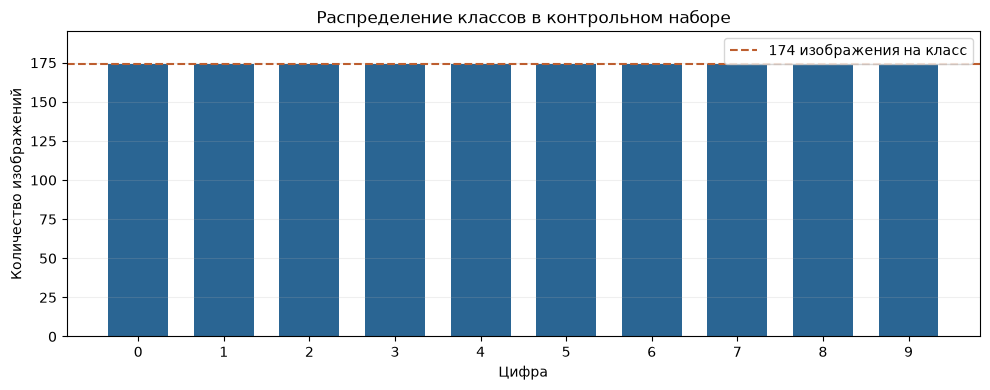

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_counts.index.astype(str), class_counts.values, color="#2a6593", width=0.7)
ax.axhline(174, linestyle="--", color="#bd5e2f", linewidth=1.5, label="174 изображения на класс")
ax.set(title="Распределение классов в контрольном наборе", xlabel="Цифра", ylabel="Количество изображений")
ax.set_ylim(0, max(195, int(class_counts.max()) + 10))
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Модульные тесты и статический анализ

Проверки запускаются теми же командами, что включены в GitHub Actions. `pytest` проверяет поведение функций, Ruff выявляет нарушения правил Python-кода, Bandit анализирует потенциально небезопасные конструкции. Данные или модель в этом разделе не изменяются.

In [4]:
test = run_check("Pytest", [sys.executable, "-m", "pytest", "tests/", "-q"])
ruff_files = [
    "src/", "tests/", "scripts/data_gate.py", "scripts/model_gate.py",
    "scripts/docker_smoke.py", "scripts/export_runtime_requirements.py",
    "scripts/security_gate.py",
]
ruff = run_check("Ruff", ["ruff", "check", *ruff_files])
bandit = run_check("Bandit", [sys.executable, "-m", "bandit", "-r", "src/", "-q"])

results["Автоматические тесты"] = test["code"] == 0
results["Ruff"] = ruff["code"] == 0
results["Bandit"] = bandit["code"] == 0
display(pd.DataFrame([
    {"Проверка": "Pytest", "Код": test["code"], "Результат": "PASS" if test["code"] == 0 else "FAIL"},
    {"Проверка": "Ruff", "Код": ruff["code"], "Результат": "PASS" if ruff["code"] == 0 else "FAIL"},
    {"Проверка": "Bandit", "Код": bandit["code"], "Результат": "PASS" if bandit["code"] == 0 else "FAIL"},
]))

Pytest: код завершения = 0
..................................................................       [100%]
66 passed in 2.48s
Ruff: код завершения = 0
All checks passed!
Bandit: код завершения = 0


,Проверка,Код,Результат
0,Pytest,0,PASS
1,Ruff,0,PASS
2,Bandit,0,PASS


## 4. Data Quality Gate — контроль качества данных

Gate проверяет обязательные поля, типы данных, диапазон пикселей 0–16, отсутствие пропусков, распределение классов и SHA256. При нарушении хотя бы одного условия программа завершается с ненулевым кодом.

In [5]:
data_ok = run_check(
    "Data Gate: исходный датасет",
    [sys.executable, "scripts/data_gate.py", "--report", "reports/lab3/notebook_data_gate.json"],
)
data_ok_report = read_json("reports/lab3/notebook_data_gate.json")
results["Data Gate — корректные данные"] = data_ok["code"] == 0 and data_ok_report["passed"]
display(pd.DataFrame([{
    "Объектов": data_ok_report.get("row_count"),
    "SHA256 совпал": data_ok_report.get("actual_sha256") == data_ok_report.get("expected_sha256"),
    "Количество классов": len(data_ok_report.get("class_counts", {})),
    "Проверка пройдена": data_ok_report.get("passed"),
}]))

Data Gate: исходный датасет: код завершения = 0
DATA GATE PASS: 1740 rows, SHA256 OK, 10 classes
Report: reports/lab3/notebook_data_gate.json


,Объектов,SHA256 совпал,Количество классов,Проверка пройдена
0,1740,True,10,True


### Демонстрация отказа: нарушена схема CSV

В тестовой копии удаляется столбец `pixel_0_0`. Исходный файл `data/digits.csv` не изменяется. Ожидаемое поведение — отказ Data Gate с кодом `1` и сообщением о несовпадении схемы.

In [6]:
with tempfile.TemporaryDirectory(prefix="lab3_data_gate_") as temporary:
    damaged_path = Path(temporary) / "digits_invalid.csv"
    frame.drop(columns=["pixel_0_0"]).to_csv(damaged_path, index=False)
    data_reject = run_check(
        "Data Gate: неверная схема",
        [
            sys.executable, "scripts/data_gate.py", "--data", str(damaged_path),
            "--report", "reports/lab3/notebook_data_gate_invalid.json",
        ],
    )
rejected_data_report = read_json("reports/lab3/notebook_data_gate_invalid.json")
schema_detected = any("CSV schema mismatch" in item for item in rejected_data_report.get("errors", []))
results["Data Gate — отказ на неверной схеме"] = data_reject["code"] == 1 and schema_detected
print("Ошибка структуры обнаружена:", schema_detected)
print("Оригинальный CSV не изменён:", hashlib.sha256(raw.read_bytes()).hexdigest() == expected_sha256)
assert results["Data Gate — отказ на неверной схеме"], "Проверка должна остановиться из-за неверной схемы"

Data Gate: неверная схема: код завершения = 1
DATA GATE FAIL:
  - SHA256 mismatch: the file differs from the pinned dataset
  - CSV schema mismatch: missing=['pixel_0_0'], extra=[], order_mismatch=False
Report: reports/lab3/notebook_data_gate_invalid.json
Ошибка структуры обнаружена: True
Оригинальный CSV не изменён: True


## 5. Model Quality Gate — контроль качества модели

В ЛР № 2 получена Accuracy около 97,41%. Политика третьей лабораторной допускает относительное снижение не более 5%: кандидат должен иметь Accuracy не ниже `baseline × 0.95`.

Программа повторно оценивает **сохранённую модель** на фиксированной контрольной части данных: 20% объектов, `random_state=42`, стратифицированное разделение. Она также проверяет SHA256 артефакта модели. Baseline при этом не перезаписывается.

In [7]:
model_ok = run_check(
    "Model Gate: сохранённая модель",
    [sys.executable, "scripts/model_gate.py", "--report", "reports/lab3/notebook_model_gate.json"],
)
model_ok_report = read_json("reports/lab3/notebook_model_gate.json")
results["Model Gate — исходная модель"] = model_ok["code"] == 0 and model_ok_report.get("passed", False)

model_weak = run_check(
    "Model Gate: слабый константный предиктор",
    [
        sys.executable, "scripts/model_gate.py", "--demo-weak-candidate",
        "--report", "reports/lab3/notebook_model_gate_weak.json",
    ],
)
model_weak_report = read_json("reports/lab3/notebook_model_gate_weak.json")
results["Model Gate — отказ слабой модели"] = (
    model_weak["code"] == 1 and model_weak_report.get("passed") is False
    and "candidate" in model_weak_report and "threshold" in model_weak_report
    and model_weak_report["candidate"] < model_weak_report["threshold"]
)

display(pd.DataFrame([
    {"Сценарий": "Сохранённая модель", "Accuracy": model_ok_report.get("candidate"),
     "Код": model_ok["code"], "Результат": "PASS" if model_ok_report.get("passed") else "FAIL"},
    {"Сценарий": "Константный предиктор (демо)", "Accuracy": model_weak_report.get("candidate"),
     "Код": model_weak["code"], "Результат": "PASS" if model_weak_report.get("passed") else "FAIL"},
]))
assert results["Model Gate — исходная модель"], "Модель не прошла проверку качества"
assert results["Model Gate — отказ слабой модели"], "Слабая модель должна быть отклонена"

Model Gate: сохранённая модель: код завершения = 0
MODEL GATE PASS: accuracy=0.974138, baseline=0.974138, threshold=0.925431
Report: reports/lab3/notebook_model_gate.json
Model Gate: слабый константный предиктор: код завершения = 1
MODEL GATE FAIL:
  candidate=0.100575, threshold=0.925431
  - Candidate accuracy is below baseline * (1 - max_relative_drop)
Report: reports/lab3/notebook_model_gate_weak.json


,Сценарий,Accuracy,Код,Результат
0,Сохранённая модель,0.974138,0,PASS
1,Константный предиктор (демо),0.100575,1,FAIL


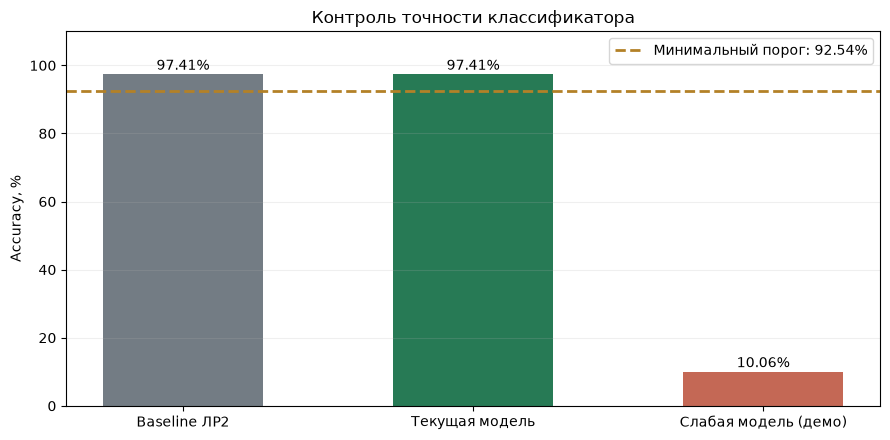

In [8]:
baseline_accuracy = float(model_ok_report["baseline"])
limit_accuracy = float(model_ok_report["threshold"])
measured_accuracy = float(model_ok_report["candidate"])
weak_accuracy = float(model_weak_report["candidate"])

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = ["Baseline ЛР2", "Текущая модель", "Слабая модель (демо)"]
values = [baseline_accuracy, measured_accuracy, weak_accuracy]
colors = ["#737c84", "#277a55", "#c46855"]
bars = ax.bar(labels, [x * 100 for x in values], color=colors, width=0.55)
ax.axhline(limit_accuracy * 100, color="#b38127", linestyle="--", linewidth=2,
           label=f"Минимальный порог: {limit_accuracy:.2%}")
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value * 100 + 1.3,
            f"{value:.2%}", ha="center", fontsize=10)
ax.set(title="Контроль точности классификатора", ylabel="Accuracy, %", ylim=(0, 110))
ax.grid(axis="y", alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Security Gate — демонстрация реакции на критическую находку

В этом опыте анализируется **синтетический отчёт**, а не намеренно уязвимый Docker-образ. Проверяются два сценария: отсутствие блокирующих находок и добавленная запись `CRITICAL`. Настоящее сканирование образа Trivy выполняется отдельно в CI.

In [9]:
fixture_pass = run_check(
    "Security Gate: тестовый отчёт без критичных находок",
    [sys.executable, "scripts/security_gate.py", "--report",
     "tests/fixtures/security_gate_input.json", "--output",
     "reports/lab3/notebook_security_gate_pass.json"],
)
fixture_fail = run_check(
    "Security Gate: синтетическая CRITICAL-находка",
    [sys.executable, "scripts/security_gate.py", "--report",
     "tests/fixtures/security_gate_critical_example.json", "--output",
     "reports/lab3/notebook_security_gate_fail.json"],
)
security_pass = read_json("reports/lab3/notebook_security_gate_pass.json")
security_fail = read_json("reports/lab3/notebook_security_gate_fail.json")
results["Security Gate — допустимый отчёт"] = fixture_pass["code"] == 0 and security_pass["passed"]
results["Security Gate — отказ CRITICAL"] = (
    fixture_fail["code"] == 1 and not security_fail["passed"]
    and any(item.get("severity") == "CRITICAL" for item in security_fail.get("blocking_findings", []))
)
display(pd.DataFrame([
    {"Сценарий": "Без блокирующих находок", "Код": fixture_pass["code"], "Допущен": security_pass["passed"]},
    {"Сценарий": "Синтетическая CRITICAL", "Код": fixture_fail["code"], "Допущен": security_fail["passed"]},
]))
assert results["Security Gate — отказ CRITICAL"], "Security Gate обязан блокировать CRITICAL"

Security Gate: тестовый отчёт без критичных находок: код завершения = 0
SECURITY GATE PASS: 1 Trivy targets checked
Report: reports/lab3/notebook_security_gate_pass.json
Security Gate: синтетическая CRITICAL-находка: код завершения = 1
SECURITY GATE FAIL
- CRITICAL SIMULATED-CRITICAL-001 (demo-package-not-installed)
Report: reports/lab3/notebook_security_gate_fail.json


,Сценарий,Код,Допущен
0,Без блокирующих находок,0,True
1,Синтетическая CRITICAL,1,False


## 7. Docker и отчёты сканирования Trivy

Приложение запускается в Docker под непривилегированным пользователем. Входной артефакт модели сверяется по SHA256. Проверка `docker run` выполняется в терминале Ubuntu; внутри ноутбука показаны параметры Dockerfile и **ранее сохранённые отчёты**. Повторная сборка или сканирование из Jupyter не требуется.

In [10]:
dockerfile = (ROOT / "Dockerfile").read_text(encoding="utf-8")
container_settings = []
for directive in ("FROM", "USER", "HEALTHCHECK", "CMD"):
    matching = [line.strip() for line in dockerfile.splitlines()
                if line.lstrip().startswith(directive + " ")]
    container_settings.append({"Параметр": directive, "Значение": matching[-1] if matching else "Не указан"})
display(pd.DataFrame(container_settings))

report_names = [
    ("Сборка Docker", "reports/lab3/docker_build_final.txt"),
    ("Smoke-предсказание", "reports/lab3/docker_smoke.txt"),
    ("Trivy — образ", "reports/lab3/trivy_image_final.txt"),
    ("Trivy — Dockerfile", "reports/lab3/trivy_dockerfile_final.txt"),
    ("pip-audit", "reports/lab3/pip_audit_runtime.json"),
]
report_rows = []
for title, location in report_names:
    report_file = ROOT / location
    report_rows.append({
        "Отчёт": title,
        "Файл": location,
        "Найден": report_file.is_file(),
        "Дата изменения": datetime.fromtimestamp(report_file.stat().st_mtime).strftime("%Y-%m-%d %H:%M")
        if report_file.is_file() else "—",
    })
display(pd.DataFrame(report_rows))

smoke_path = ROOT / "reports/lab3/docker_smoke.txt"
if smoke_path.is_file():
    print("Выдержка из сохранённой smoke-проверки:")
    print("\n".join(smoke_path.read_text(encoding="utf-8", errors="replace").splitlines()[-5:]))

,Параметр,Значение
0,FROM,FROM python:3.12.16-slim-trixie
1,USER,USER 10001:10001
2,HEALTHCHECK,HEALTHCHECK --interval=60s --timeout=20s --ret...
3,CMD,"CMD [""python"", ""-m"", ""scripts.docker_smoke""]"


,Отчёт,Файл,Найден,Дата изменения
0,Сборка Docker,reports/lab3/docker_build_final.txt,True,2026-11-05 15:22
1,Smoke-предсказание,reports/lab3/docker_smoke.txt,True,2026-11-05 13:48
2,Trivy — образ,reports/lab3/trivy_image_final.txt,True,2026-11-05 15:24
3,Trivy — Dockerfile,reports/lab3/trivy_dockerfile_final.txt,True,2026-11-05 15:20
4,pip-audit,reports/lab3/pip_audit_runtime.json,True,2026-11-05 15:47


Выдержка из сохранённой smoke-проверки:
SMOKE PASS: uid=10001, prediction=0, model_sha256=655ada9ced68462b56dc298ad18bba5e2c2b4fe9783181aef8067ffd3467c9a9


## 8. Автоматизация в GitHub Actions

CI-файл `.github/workflows/ci.yml` предусматривает последовательность: проверка исходников → зависимости → Ruff → Bandit → pytest → pip-audit → Data Gate → Model Gate → сборка Docker → Trivy → smoke → сохранение отчётов.

При сбое обязательного этапа последующие проверки не выполняются. Отчёты сохраняются независимо от результата запуска. Реальные статусы `success`/`failure` и пропущенные этапы подтверждаются **на странице GitHub Actions по конкретному коммиту**, а не запуском этого ноутбука.

In [11]:
workflow_path = ROOT / ".github/workflows/ci.yml"
if workflow_path.is_file():
    workflow_text = workflow_path.read_text(encoding="utf-8")
    stages = re.findall(r'^\s+- name:\s+["\']?(\d{2}\s*-\s*[^"\'\n]+)', workflow_text, re.MULTILINE)
    if not stages:
        stages = re.findall(r'^\s+- name:\s*(.+)$', workflow_text, re.MULTILINE)
    display(pd.DataFrame({"№": range(1, len(stages) + 1), "Этап CI": stages}))
else:
    print("Файл GitHub Actions отсутствует в рабочем каталоге.")

commit = run_check("Коммит проекта", ["git", "rev-parse", "--short", "HEAD"])
branch = run_check("Текущая ветка", ["git", "branch", "--show-current"])
print("Ссылка на действия:", "https://github.com/Serega-Rodriguez-Sand-Kingovich/lab1-cyber-resilience/actions")

,№,Этап CI
0,1,01 - Checkout sources without persisted creden...
1,2,02 - Python 3.12
2,3,03 - Prepare CI reports and provenance
3,4,04 - Install locked runtime and CI tools
4,5,05 - Ruff lint (mandatory)
5,6,06 - Bandit security analysis (mandatory)
6,7,07 - Pytest unit and integration tests (mandat...
7,8,08 - pip-audit runtime dependencies (mandatory)
8,9,09 - Data quality gate (mandatory)
9,10,10 - Model quality gate (mandatory)


Коммит проекта: код завершения = 0
c474595
Текущая ветка: код завершения = 0
lab3-ci
Ссылка на действия: https://github.com/Serega-Rodriguez-Sand-Kingovich/lab1-cyber-resilience/actions


## 9. Результаты лабораторной работы

Таблица ниже составляется из фактических результатов текущего выполнения. Отрицательные тестовые сценарии считаются успешными **только тогда, когда проверка правильно отказала**. Статусы удалённых запусков GitHub Actions оцениваются отдельно.

In [12]:
summary = pd.DataFrame([
    {"Проверка": name, "Результат": "ВЫПОЛНЕНО" if passed else "НЕ ПРОЙДЕНО"}
    for name, passed in results.items()
])
display(summary)

passed_count = int(summary["Результат"].eq("ВЫПОЛНЕНО").sum())
all_count = len(summary)
if passed_count == all_count:
    text = (
        f"**Вывод по локальной демонстрации.** Выполнено {passed_count} из {all_count} "
        "проверок. Корректные данные и исходная модель прошли контроль; "
        "нарушение схемы, слабая модель и синтетическая критическая находка "
        "были отклонены. Для завершения ЛР № 3 необходимо отдельно подтвердить "
        "успешный и три неуспешных запуска на GitHub Actions."
    )
else:
    text = (
        f"**Вывод по локальной демонстрации.** Выполнено {passed_count} из {all_count} "
        "проверок. Есть замечания, которые требуется устранить до защиты. "
        "Статусы GitHub Actions подтверждаются отдельно."
    )
display(Markdown(text))

,Проверка,Результат
0,Хэш датасета,ВЫПОЛНЕНО
1,Автоматические тесты,ВЫПОЛНЕНО
2,Ruff,ВЫПОЛНЕНО
3,Bandit,ВЫПОЛНЕНО
4,Data Gate — корректные данные,ВЫПОЛНЕНО
5,Data Gate — отказ на неверной схеме,ВЫПОЛНЕНО
6,Model Gate — исходная модель,ВЫПОЛНЕНО
7,Model Gate — отказ слабой модели,ВЫПОЛНЕНО
8,Security Gate — допустимый отчёт,ВЫПОЛНЕНО
9,Security Gate — отказ CRITICAL,ВЫПОЛНЕНО


**Вывод по локальной демонстрации.** Выполнено 10 из 10 проверок. Корректные данные и исходная модель прошли контроль; нарушение схемы, слабая модель и синтетическая критическая находка были отклонены. Для завершения ЛР № 3 необходимо отдельно подтвердить успешный и три неуспешных запуска на GitHub Actions.